# Restaurant Dataset - Predictive Modeling

### Level 3 - Task 1

In [15]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import LabelEncoder

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import matplotlib.pyplot as plt
import seaborn as sns

In [16]:
df = pd.read_csv("../Engineered_Dataset.csv")

df.head()

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Rating text,Votes,Restaurant Name Length,Address Length,Cuisine Count,Has Table Booking,Has Online Delivery,Rating Category,Cost Per Vote,Has Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Excellent,314,16,71,3,1,0,Excellent,3.492063,1
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Excellent,591,16,67,1,1,0,Good,2.027027,1
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Very Good,270,22,56,4,1,0,Good,14.760148,1
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Excellent,365,4,70,2,0,0,Excellent,4.098361,1
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Excellent,229,11,64,2,1,0,Excellent,6.521739,1


In [17]:
#select features that shouldn't be used for prediction
drop_columns = [
    "Restaurant ID",
    "Restaurant Name",
    "Address",
    "Locality",
    "Locality Verbose",
    "Rating text",
    "Rating color",
    "Aggregate rating",
    "Rating Category"
]

X = df.drop(columns=drop_columns)

y = df["Aggregate rating"]

In [18]:
# Encode Categorical Variables
label_encoder = LabelEncoder()

for column in X.select_dtypes(include="object").columns:
    X[column] = label_encoder.fit_transform(X[column].astype(str))

C:\Users\yadid\AppData\Local\Temp\ipykernel_25420\189385786.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in X.select_dtypes(include="object").columns:


In [19]:
#Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

### Linear Regression Model

In [20]:

lr = LinearRegression()

lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)

### Decision Tree

In [21]:
dt = DecisionTreeRegressor(random_state=42)

dt.fit(X_train, y_train)

dt_pred = dt.predict(X_test)

### Random Forest

In [22]:
rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

### Evaluation Function

In [23]:
def evaluate_model(y_true, y_pred):

    mae = mean_absolute_error(y_true, y_pred)

    mse = mean_squared_error(y_true, y_pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_true, y_pred)

    return [mae, mse, rmse, r2]

In [24]:
#Compare Models
results = pd.DataFrame(
    {
        "Model": [
            "Linear Regression",
            "Decision Tree",
            "Random Forest"
        ],

        "MAE": [
            evaluate_model(y_test, lr_pred)[0],
            evaluate_model(y_test, dt_pred)[0],
            evaluate_model(y_test, rf_pred)[0]
        ],

        "MSE": [
            evaluate_model(y_test, lr_pred)[1],
            evaluate_model(y_test, dt_pred)[1],
            evaluate_model(y_test, rf_pred)[1]
        ],

        "RMSE": [
            evaluate_model(y_test, lr_pred)[2],
            evaluate_model(y_test, dt_pred)[2],
            evaluate_model(y_test, rf_pred)[2]
        ],

        "R² Score": [
            evaluate_model(y_test, lr_pred)[3],
            evaluate_model(y_test, dt_pred)[3],
            evaluate_model(y_test, rf_pred)[3]
        ]
    }
)

results

,Model,MAE,MSE,RMSE,R² Score
0,Linear Regression,0.682828,0.891246,0.944058,0.608435
1,Decision Tree,0.274621,0.179163,0.423276,0.921286
2,Random Forest,0.191464,0.085639,0.292642,0.962375


In [25]:
# Sort Results by R² Score
results.sort_values(
    by="R² Score",
    ascending=False
)

,Model,MAE,MSE,RMSE,R² Score
2,Random Forest,0.191464,0.085639,0.292642,0.962375
1,Decision Tree,0.274621,0.179163,0.423276,0.921286
0,Linear Regression,0.682828,0.891246,0.944058,0.608435


In [26]:
#Feature Importance for Random Forest Model
importance = pd.Series(
    rf.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

importance.head(10)

Votes                     0.942589
Longitude                 0.009789
Latitude                  0.009752
Cost Per Vote             0.009259
Cuisines                  0.007459
Address Length            0.005046
Average Cost for two      0.004166
Restaurant Name Length    0.004015
Country Code              0.002186
City                      0.001564
dtype: float64

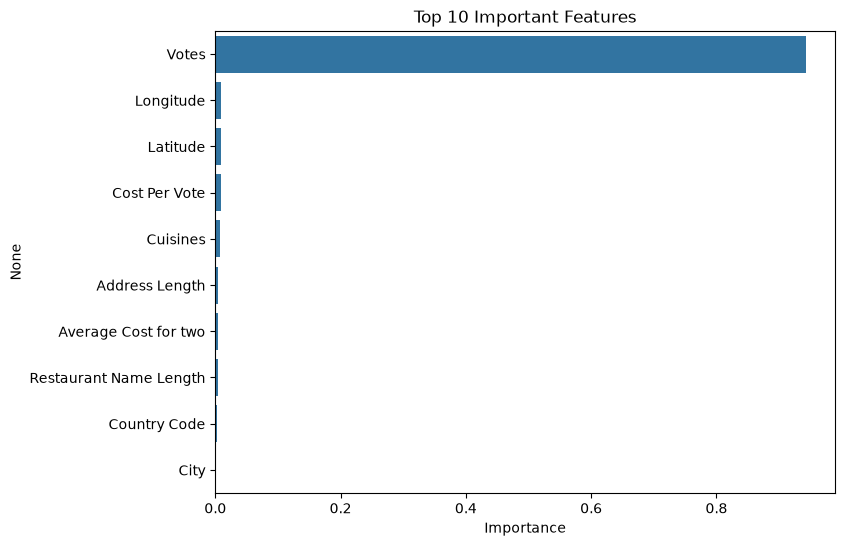

In [27]:

plt.figure(figsize=(8,6))

sns.barplot(
    x=importance.head(10).values,
    y=importance.head(10).index
)

plt.title("Top 10 Important Features")

plt.xlabel("Importance")

plt.show()

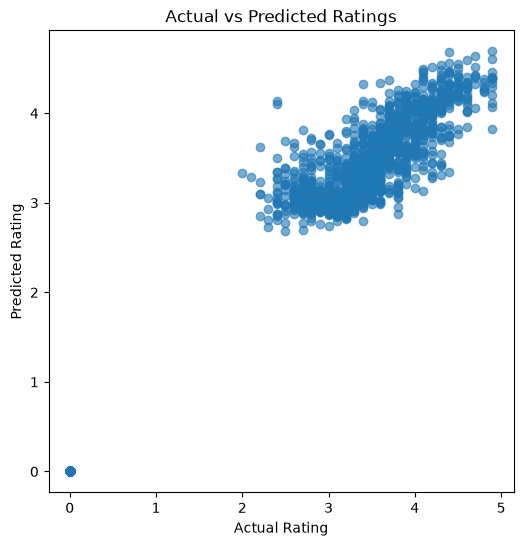

In [28]:
# Actual vs Predicted Ratings for Random Forest Model
plt.figure(figsize=(6,6))

plt.scatter(
    y_test,
    rf_pred,
    alpha=0.6
)

plt.xlabel("Actual Rating")
plt.ylabel("Predicted Rating")
plt.title("Actual vs Predicted Ratings")

plt.show()

## Model Comparison

- Three regression algorithms were trained.
- Performance was evaluated using MAE, MSE, RMSE, and R² Score.
- Random Forest achieved the best overall performance.
- Feature importance analysis identified the variables that most influenced restaurant ratings.